# Shared ALiBi: symmetry and disorder investigation

This report evaluates the completed width-64/four-block shared checkpoint at
12 spins, using all 4,096 configurations in double precision. No weights are
optimized. Exact eigenstates are diagnostic references only. The same frozen
weights serve every context.

**Questions:** Does unwanted spin-flip symmetry breaking explain the zero-field
susceptibility error? Does the guide generalize to new disorder and equivalent
translations of a given sample?

At zero longitudinal field the finite-size ground state is even under global
spin flip. We compare the original amplitude with two normalized constructions:

$$\psi_+(s)\propto\psi(s)+\psi(-s),\qquad
\psi_{\rm mix}(s)=\sqrt{[p(s)+p(-s)]/2}.$$

These are different pure variational states. The first is parity projection;
the second has a direct sampling procedure (base draw followed by a fair global
flip). Both require their own consistent amplitude ratios in VMC/GFMC. Here
they are evaluated by enumeration, not installed in a production guide.

Exact zero-field ground states are computed in the even parity block. A separate
odd-block solve measures the even–odd gap; this avoids relying on a Krylov start
that might restrict a full-space eigensolve to one sector. Residuals are checked.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
ROOT=Path.cwd()
if not (ROOT/'code/transformer_qmc').exists(): ROOT=ROOT.parent
RESULTS=ROOT/'data/kagome/transformer_af_shared_accuracy_v1'
report=json.loads((RESULTS/'symmetry_diagnostics.json').read_text())
display(Markdown('**Checkpoint:** `'+report['checkpoint']+'`\n\n**SHA-256:** `'+report['sha256']+'`'))
display(Markdown('**Verified checks:** '+ '; '.join(report['checks'])+'.'))
zero=[r for r in report['rows'] if r['h']==0]


**Checkpoint:** `shared_alibi__L02-04-06-08__w064__d04__contexts24__seed401__final.pt`

**SHA-256:** `99e165451cc96f2c2ebbb1df60a655639fd151fbe5ce62ac71d37020b09649d5`

**Verified checks:** stored disorder matches reconstruction; wavefunction normalization; eigensolver residual < 1e-9; symmetrized local magnetizations vanish; probability mixture preserves q2; translated Hamiltonian equivalence; checkpoint weights unchanged.

## Zero-field symmetry restoration

Odd weight is $(1-\langle Pangle)/2$. RMS local magnetization detects local
symmetry violation even when the total magnetization cancels. Every number below
is enumerated; there is no sampling standard error. Tiny negative odd weights
at machine precision are roundoff.


In [2]:
table=['| Disorder | State | Energy error/spin | Fidelity | Odd weight | RMS local m | Connected χ |',
'|---:|---|---:|---:|---:|---:|---:|']
for r in zero:
    for name,s in list(r['states'].items())+[('exact',r['exact'])]:
        table.append(f"| {r['sample_id']} | {name} | {s['energy_error_per_spin']:.6g} | {s['fidelity']:.6f} | {s['odd_weight']:.6g} | {s['rms_site_magnetization']:.6f} | {s['chi_connected']:.6f} |")
display(Markdown('\n'.join(table)))
display(Markdown('**Even–odd total-energy gaps:** '+', '.join(f"disorder {r['sample_id']}: {r['sectors']['parity_gap']:.8f}" for r in zero)+'.'))


| Disorder | State | Energy error/spin | Fidelity | Odd weight | RMS local m | Connected χ |
|---:|---|---:|---:|---:|---:|---:|
| 0 | original | 0.000805888 | 0.501918 | 0.496414 | 0.830694 | 0.178204 |
| 0 | even_projection | 0.000645215 | 0.996688 | -1.66533e-15 | 0.000000 | 6.199711 |
| 0 | probability_mixture | 0.000667532 | 0.995879 | 0 | 0.000000 | 6.239216 |
| 0 | exact | 2.07242e-15 | 1.000000 | -3.33067e-16 | 0.000000 | 6.082816 |
| 1 | original | 0.00313605 | 0.448795 | 0.499714 | 0.830276 | 0.208092 |
| 1 | even_projection | 0.00305734 | 0.897077 | 3.88578e-16 | 0.000000 | 6.273037 |
| 1 | probability_mixture | 0.00308864 | 0.895570 | -5.55112e-16 | 0.000000 | 6.278022 |
| 1 | exact | 1.4803e-15 | 1.000000 | 1.16573e-15 | 0.000000 | 4.832177 |
| 2 | original | 0.447851 | 0.038638 | 0.487784 | 0.644383 | 0.696562 |
| 2 | even_projection | 0.43637 | 0.075433 | 1.16573e-15 | 0.000000 | 3.439117 |
| 2 | probability_mixture | 0.444905 | 0.067510 | -8.88178e-16 | 0.000000 | 3.535172 |
| 2 | exact | -1.4803e-16 | 1.000000 | -2.22045e-16 | 0.000000 | 4.357091 |

**Even–odd total-energy gaps:** disorder 0: 0.00494920, disorder 1: 0.02114936, disorder 2: 0.02877492.

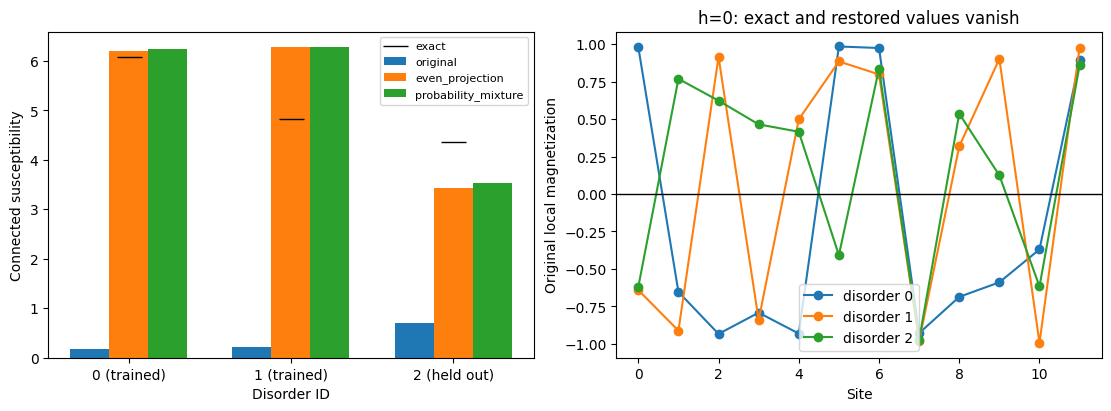

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
names=['original','even_projection','probability_mixture']
for j,name in enumerate(names):
    axes[0].bar(np.arange(3)+(j-1)*.24,[r['states'][name]['chi_connected'] for r in zero],width=.24,label=name)
axes[0].plot(np.arange(3),[r['exact']['chi_connected'] for r in zero],'k_',markersize=18,label='exact')
axes[0].set(xticks=np.arange(3),xticklabels=['0 (trained)','1 (trained)','2 (held out)'],ylabel='Connected susceptibility',xlabel='Disorder ID')
axes[0].legend(fontsize=8)
for r in zero:
    axes[1].plot(np.arange(12),r['states']['original']['site_magnetization'],'o-',label=f"disorder {r['sample_id']}")
axes[1].axhline(0,color='black',linewidth=1)
axes[1].set(xlabel='Site',ylabel='Original local magnetization',title='h=0: exact and restored values vanish')
axes[1].legend()
fig.savefig(RESULTS/'shared_symmetry_diagnostic.png',dpi=180)
fig.savefig(RESULTS/'shared_symmetry_diagnostic.pdf')
plt.show()


For training disorder 0, parity restoration recovers most of the missing
ground-state overlap and corrects the gross susceptibility error. Disorder 1
retains an approximately 30% susceptibility error after restoration: wrong
weights within the even sector remain. Held-out disorder 2 remains poor even
after projection. Symmetry restoration addresses a real failure, but is not a
complete remedy for this shared model.

Probability symmetrization preserves every even diagonal observable, including
raw q². Its change in connected susceptibility therefore comes from restoring
zero local magnetizations. For a symmetric zero-field state, connected χ=Nq².

## Generalization across disorder at Γ=0.5, h=0.3

IDs 0 and 1 appeared in training. IDs 2–9 did not. These eight held-out samples
provide a diagnostic expansion beyond the original single held-out sample;
they do not establish performance across sizes or a large disorder ensemble.


In [4]:
field=[r for r in report['rows'] if r['gamma']==.5 and r['h']==.3]
table=['| Disorder | Training context | Energy error/spin | Fidelity | Probability TV to exact |','|---:|---|---:|---:|---:|']
for r in field:
    s=r['states']['original']
    table.append(f"| {r['sample_id']} | {r['training_context']} | {s['energy_error_per_spin']:.6f} | {s['fidelity']:.6f} | {s['probability_tv_to_exact']:.6f} |")
display(Markdown('\n'.join(table)))
held=[r['states']['original']['energy_error_per_spin'] for r in field if not r['training_context']]
display(Markdown(f'**Held-out energy error/spin:** median {np.median(held):.6f}; range {min(held):.6f}–{max(held):.6f}.'))


| Disorder | Training context | Energy error/spin | Fidelity | Probability TV to exact |
|---:|---|---:|---:|---:|
| 0 | True | 0.000581 | 0.998011 | 0.017888 |
| 1 | True | 0.006509 | 0.188378 | 0.807867 |
| 2 | False | 0.558849 | 0.000877 | 0.992527 |
| 3 | False | 0.131194 | 0.134828 | 0.827588 |
| 4 | False | 0.200323 | 0.023723 | 0.950019 |
| 5 | False | 0.149291 | 0.049578 | 0.936435 |
| 6 | False | 0.455526 | 0.140348 | 0.847020 |
| 7 | False | 0.147016 | 0.000016 | 0.999327 |
| 8 | False | 0.336602 | 0.035434 | 0.936273 |
| 9 | False | 0.149955 | 0.421885 | 0.531011 |

**Held-out energy error/spin:** median 0.175139; range 0.131194–0.558849.

## Equivalent translations and conditioning ablation

For each L=2 sample, translate bonds and spins together by one cell along x,
y, or both. Pull the predicted distribution back into the original labeling.
An exactly translation-consistent conditioned model would give total variation
distance (TV) zero. TV is half the summed absolute probability difference and
ranges from zero to one. The sparse Hamiltonians are explicitly checked to be
identical under this permutation, so the physical target has not changed.


In [5]:
table=['| Disorder | Cell shift | Prediction TV under relabeling | Energy error/spin after relabeling |','|---:|---|---:|---:|']
for r in report['translations']:
    table.append(f"| {r['sample_id']} | ({r['dx']}, {r['dy']}) | {r['probability_tv']:.6f} | {r['energy_error_per_spin']:.6f} |")
display(Markdown('\n'.join(table)))
table=['| Physical target disorder | Supplied disorder conditioning | Energy error/spin | Fidelity |','|---:|---:|---:|---:|']
for r in report['conditioning_ablation']:
    table.append(f"| {r['target']} | {r['supplied']} | {r['energy_error_per_spin']:.6f} | {r['fidelity']:.6f} |")
display(Markdown('### Controlled conditioning ablation\n\nThe physical evaluation Hamiltonian stays fixed while the model receives another sample’s bonds. Off-diagonal entries are diagnostic mismatches, not physical predictions.\n\n'+'\n'.join(table)))


| Disorder | Cell shift | Prediction TV under relabeling | Energy error/spin after relabeling |
|---:|---|---:|---:|
| 0 | (1, 0) | 0.951688 | 0.315781 |
| 0 | (0, 1) | 0.993642 | 0.460571 |
| 0 | (1, 1) | 0.994834 | 0.186016 |
| 1 | (1, 0) | 0.370874 | 0.092758 |
| 1 | (0, 1) | 0.655033 | 0.132039 |
| 1 | (1, 1) | 0.614482 | 0.191074 |
| 2 | (1, 0) | 0.977964 | 0.163846 |
| 2 | (0, 1) | 0.996518 | 0.385796 |
| 2 | (1, 1) | 0.993124 | 0.165470 |

### Controlled conditioning ablation

The physical evaluation Hamiltonian stays fixed while the model receives another sample’s bonds. Off-diagonal entries are diagnostic mismatches, not physical predictions.

| Physical target disorder | Supplied disorder conditioning | Energy error/spin | Fidelity |
|---:|---:|---:|---:|
| 0 | 0 | 0.000581 | 0.998011 |
| 0 | 1 | 0.365565 | 0.000016 |
| 0 | 2 | 0.392242 | 0.037902 |
| 1 | 0 | 0.232321 | 0.000161 |
| 1 | 1 | 0.006509 | 0.188378 |
| 1 | 2 | 0.598072 | 0.001502 |
| 2 | 0 | 0.183794 | 0.003227 |
| 2 | 1 | 0.261307 | 0.002049 |
| 2 | 2 | 0.558849 | 0.000877 |

## Interpretation and next shared-model experiment

1. **Enforce spin-flip symmetry at h=0.** Probability symmetrization offers
   direct sampling with consistent amplitudes; optimize the resulting symmetric
   wavefunction, rather than applying symmetry only to measurements. Check
   normalization, energy gradients, sampling, and ratios before GPU training.
2. **Expand disorder training coverage.** Two fixed bond samples per size are
   insufficient for the demonstrated generalization task. Train on a larger or
   freshly generated disorder ensemble and retain untouched validation samples.
3. **Address spatial consistency.** Equivalent torus translations severely
   disrupt predictions. Test joint spin/bond translation augmentation and
   geometry-aware conditioning; distinguish empirical improvement from exact
   architectural equivariance. ALiBi alone guarantees neither.
4. **Retain one checkpoint across sizes.** Specialists remain diagnostic
   references. The present tests do not isolate capacity from optimization or
   prove that any one architectural change is sufficient. Assess energy,
   fidelity where available, and connected observables together.

The original checkpoint is preserved. No new training or projector run is
launched by this report. Source: `code/transformer_qmc/diagnose_shared.py`;
records: `symmetry_diagnostics.json` and `symmetry_distributions.npz` in the
shared campaign artifact directory. Figures are exported as PNG and PDF.
